# SALR experiments (Nour)

The optimizer lives in `recommender/salr.py` (tests: `tests/test_salr.py`) and the
evaluator in `recommender/evaluate.py`. This notebook only **runs** them.

Protocol (task distribution §4): `k = 32`, batch 256, seeds 616/617/618 with the shared
initialization, budget and checkpoints in cumulative triplet-gradient work, checkpoint
chosen by ordinary-validation NDCG@10 only. No test data is touched here.

> **Provisional regularization.** The shared `(lambda_f, lambda_w)` has not been chosen yet
> (Phase 3). Everything below uses `1e-3 / 1e-3`; rerun the grid once the pair is fixed.

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

from recommender.data import load_dataset
from recommender.evaluate import evaluate_ranking, make_evaluator, select_checkpoint
from recommender.salr import SALRConfig, train_salr
from recommender.sgd import SGDConfig, train_sgd

ds = load_dataset()
evaluate = make_evaluator(ds)
SEEDS = (616, 617, 618)
LAMBDA_F, LAMBDA_W = 1e-3, 1e-3          # provisional, see note above
TOTAL_WORK, CHECKPOINT_EVERY = 1_000_000, 20_000
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
print(ds.summary())

customers            170
products             286  ordinary=206  cold_validation=40  cold_test=40
text vectors Z       (286, 384) float64
train reviews        1897
validation reviews   358
test reviews         362
train triplets       5436
validation triplets  121
eval ordinary validation  121 customers, 121 relevant products
eval ordinary test        110 customers, 110 relevant products
eval cold     validation  119 customers, 217 relevant products
eval cold     test        114 customers, 217 relevant products


## Reference points on ordinary validation

In [2]:
popularity = ds.train_positive_counts().astype(float)
pop = evaluate_ranking(lambda u, ids: popularity[ids], ds, "ordinary", "validation")
rnd = [evaluate_ranking(lambda u, ids, r=np.random.default_rng(s): r.random(len(ids)),
                        ds, "ordinary", "validation") for s in SEEDS]
print(f"popularity  NDCG@10={pop['ndcg']:.4f}  Recall@10={pop['recall']:.4f}")
print(f"random      NDCG@10={np.mean([r['ndcg'] for r in rnd]):.4f}  (mean of 3 seeds)")

popularity  NDCG@10=0.0817  Recall@10=0.1983
random      NDCG@10=0.0240  (mean of 3 seeds)


## Tuning grid

* `base_lr` in {0.5, 1, 2, 4, 8, 16, 32}
* probes: one step each way (`n = 1`), or two steps each way (`n = 2`) with `probe_step` 0.05 or 0.5
* probe every update (`probe_every = 1`)

With `n = 1`, `S ≈ 2·probe_step·|g|` and `probe_step` almost cancels in `S / median(S)`
(only higher-order terms remain), so it is barely a free parameter there (checked in the next cell). Every configuration runs on all three
seeds; failed runs are kept in the table.

In [3]:
def run(cfg, seed):
    with np.errstate(all="ignore"):
        log = train_salr(ds, seed, cfg, TOTAL_WORK, CHECKPOINT_EVERY, evaluate)
    best = select_checkpoint(log) if log["checkpoints"] else None
    lr = np.array(log["lr"])
    return log, {
        "base_lr": cfg.base_lr, "n_probe": cfg.n_descent, "probe_step": cfg.probe_step, "seed": seed,
        "status": log["status"], "best_ndcg": best["val_ndcg"], "best_recall": best["val_recall"],
        "best_work": best["work"], "best_val_loss": best["val_loss"], "best_train_loss": best["train_loss"],
        "updates_at_best": best["updates"], "train_time_s": log["checkpoints"][-1]["train_time"],
        "lr_median": float(np.median(lr)), "lr_max": float(lr.max()),
        "invalid_probes": int(np.sum(np.array(log["probed"]) & ~np.array(log["valid"]))),
    }

# probe_step nearly cancels with one-step probes
a, _ = run(SALRConfig(2.0, 0.05, LAMBDA_F, LAMBDA_W), 616)
b, _ = run(SALRConfig(2.0, 0.5, LAMBDA_F, LAMBDA_W), 616)
print("max |lr(step 0.05) - lr(step 0.5)| =", np.max(np.abs(np.array(a["lr"]) - np.array(b["lr"]))))

max |lr(step 0.05) - lr(step 0.5)| = 0.022387845705437392


In [ ]:
grid = [SALRConfig(lr, 0.05, LAMBDA_F, LAMBDA_W) for lr in (0.5, 1, 2, 4, 8, 16, 32)]
grid += [SALRConfig(lr, step, LAMBDA_F, LAMBDA_W, n_descent=2, n_ascent=2)
         for lr in (0.5, 1, 2, 4, 8, 16, 32) for step in (0.05, 0.5)]

started, logs, rows = time.perf_counter(), {}, []
for cfg in grid:
    for seed in SEEDS:
        log, row = run(cfg, seed)
        logs[(cfg, seed)] = log
        rows.append(row)
runs = pd.DataFrame(rows)
runs.to_csv(RESULTS / "salr_tuning_runs.csv", index=False)
print(f"{len(rows)} runs, {sum(r['train_time_s'] for r in rows):.0f}s of training time, "
      f"{time.perf_counter() - started:.0f}s wall-clock including evaluation")
print("total tuning work:", f"{len(rows) * TOTAL_WORK:,}", "triplet-gradients")

In [5]:
summary = (runs.groupby(["n_probe", "probe_step", "base_lr"])
           .agg(mean_ndcg=("best_ndcg", "mean"), std_ndcg=("best_ndcg", "std"),
                mean_recall=("best_recall", "mean"), mean_val_loss=("best_val_loss", "mean"),
                mean_best_work=("best_work", "mean"), failed=("status", lambda s: int((s != "ok").sum())),
                lr_max=("lr_max", "max"))
           .reset_index().sort_values("mean_ndcg", ascending=False))
summary.to_csv(RESULTS / "salr_tuning_summary.csv", index=False)
summary.round(4)

,n_probe,probe_step,base_lr,mean_ndcg,std_ndcg,mean_recall,mean_val_loss,mean_best_work,failed,lr_max
5,1,0.05,16.0,0.1425,0.0011,0.2452,0.5358,746780.0000,0,52.5743
13,2,0.05,32.0,0.1417,0.0088,0.2369,0.5553,353792.0000,0,94.4830
20,2,0.50,32.0,0.1411,0.0083,0.2369,0.5555,353792.0000,0,94.8101
6,1,0.05,32.0,0.1401,0.0034,0.2369,0.5558,613460.0000,0,94.4793
4,1,0.05,8.0,0.1393,0.0028,0.2645,0.5413,500157.3333,0,25.1007
3,1,0.05,4.0,0.1376,0.0035,0.2590,0.5505,506722.6667,0,13.2945
12,2,0.05,16.0,0.1364,0.0026,0.2507,0.5454,440512.0000,0,52.5745
19,2,0.50,16.0,0.1364,0.0026,0.2534,0.5514,347016.0000,0,52.5426
18,2,0.50,8.0,0.1337,0.0033,0.2507,0.5463,786880.0000,0,25.1252
11,2,0.05,8.0,0.1336,0.0032,0.2507,0.5463,786880.0000,0,25.1010


## Selected configuration (by mean selected-checkpoint ordinary-validation NDCG@10)

In [6]:
top = summary.iloc[0]
chosen = next(c for c in grid if (c.base_lr, c.n_descent, c.probe_step) ==
              (top.base_lr, top.n_probe, top.probe_step))
print(chosen)
runs[(runs.base_lr == chosen.base_lr) & (runs.n_probe == chosen.n_descent)
     & (runs.probe_step == chosen.probe_step)].round(4)

SALRConfig(base_lr=16, probe_step=0.05, lambda_f=0.001, lambda_w=0.001, n_descent=1, n_ascent=1, probe_every=1, batch_size=256)


,base_lr,n_probe,probe_step,seed,status,best_ndcg,best_recall,best_work,best_val_loss,best_train_loss,updates_at_best,train_time_s,lr_median,lr_max,invalid_probes
15,16.0,1,0.05,616,ok,0.1435,0.2645,900012,0.5475,0.2351,3642,9.2380,15.8340,48.3119,0
16,16.0,1,0.05,617,ok,0.1413,0.2314,860168,0.5323,0.2378,3481,8.5651,15.8620,52.5743,0
17,16.0,1,0.05,618,ok,0.1428,0.2397,480160,0.5275,0.2410,1943,7.5480,15.8454,44.8929,0


## Same budget with plain SGD (reference only; SGD tuning is Mohamed's)

In [7]:
sgd_rows = []
for lr in (1.0, 2.0, 4.0):
    for seed in SEEDS:
        with np.errstate(all="ignore"):
            log = train_sgd(ds, seed, SGDConfig(lr, LAMBDA_F, LAMBDA_W), TOTAL_WORK, CHECKPOINT_EVERY, evaluate)
        best = select_checkpoint(log)
        logs[("sgd", lr, seed)] = log
        sgd_rows.append({"lr": lr, "seed": seed, "status": log["status"],
                         "best_ndcg": best["val_ndcg"], "best_work": best["work"]})
sgd = pd.DataFrame(sgd_rows)
sgd.groupby("lr").agg(mean_ndcg=("best_ndcg", "mean"), std_ndcg=("best_ndcg", "std"),
                      failed=("status", lambda s: int((s != "ok").sum()))).round(4)

,mean_ndcg,std_ndcg,failed
lr,,,
1.0,0.1258,0.0018,0
2.0,0.1321,0.0005,0
4.0,0.1340,0.0041,0


## Figures

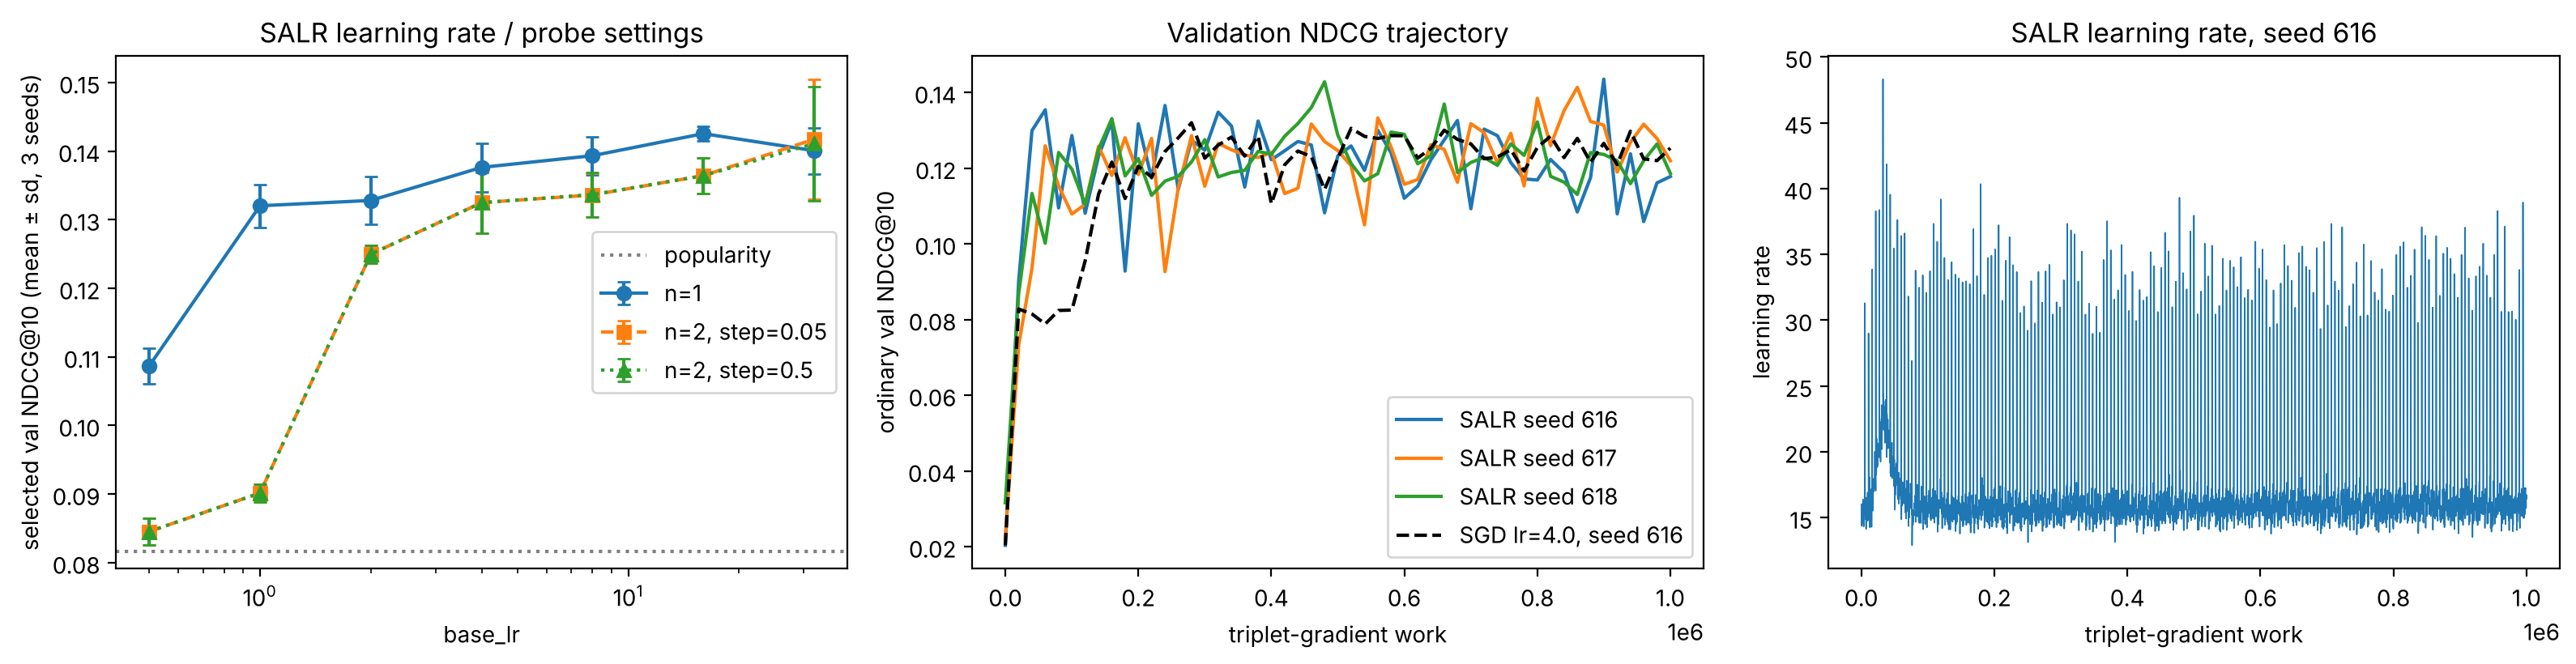

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for n, step, style in ((1, 0.05, "-o"), (2, 0.05, "--s"), (2, 0.5, ":^")):
    part = summary[(summary.n_probe == n) & (summary.probe_step == step)].sort_values("base_lr")
    axes[0].errorbar(part.base_lr, part.mean_ndcg, yerr=part.std_ndcg, fmt=style, capsize=3,
                     label=f"n={n}" + ("" if n == 1 else f", step={step}"))
axes[0].axhline(pop["ndcg"], color="grey", ls=":", label="popularity")
axes[0].set(xscale="log", xlabel="base_lr", ylabel="selected val NDCG@10 (mean ± sd, 3 seeds)",
            title="SALR learning rate / probe settings")
axes[0].legend()

for seed in SEEDS:
    ck = logs[(chosen, seed)]["checkpoints"]
    axes[1].plot([c["work"] for c in ck], [c["val_ndcg"] for c in ck], label=f"SALR seed {seed}")
best_sgd_lr = sgd.groupby("lr").best_ndcg.mean().idxmax()
ck = logs[("sgd", best_sgd_lr, 616)]["checkpoints"]
axes[1].plot([c["work"] for c in ck], [c["val_ndcg"] for c in ck], "k--", label=f"SGD lr={best_sgd_lr}, seed 616")
axes[1].set(xlabel="triplet-gradient work", ylabel="ordinary val NDCG@10", title="Validation NDCG trajectory")
axes[1].legend()

log = logs[(chosen, 616)]
axes[2].plot(log["work"], log["lr"], lw=0.6)
axes[2].set(xlabel="triplet-gradient work", ylabel="learning rate", title="SALR learning rate, seed 616")
fig.tight_layout(); fig.savefig(RESULTS / "salr_tuning.png", dpi=150)

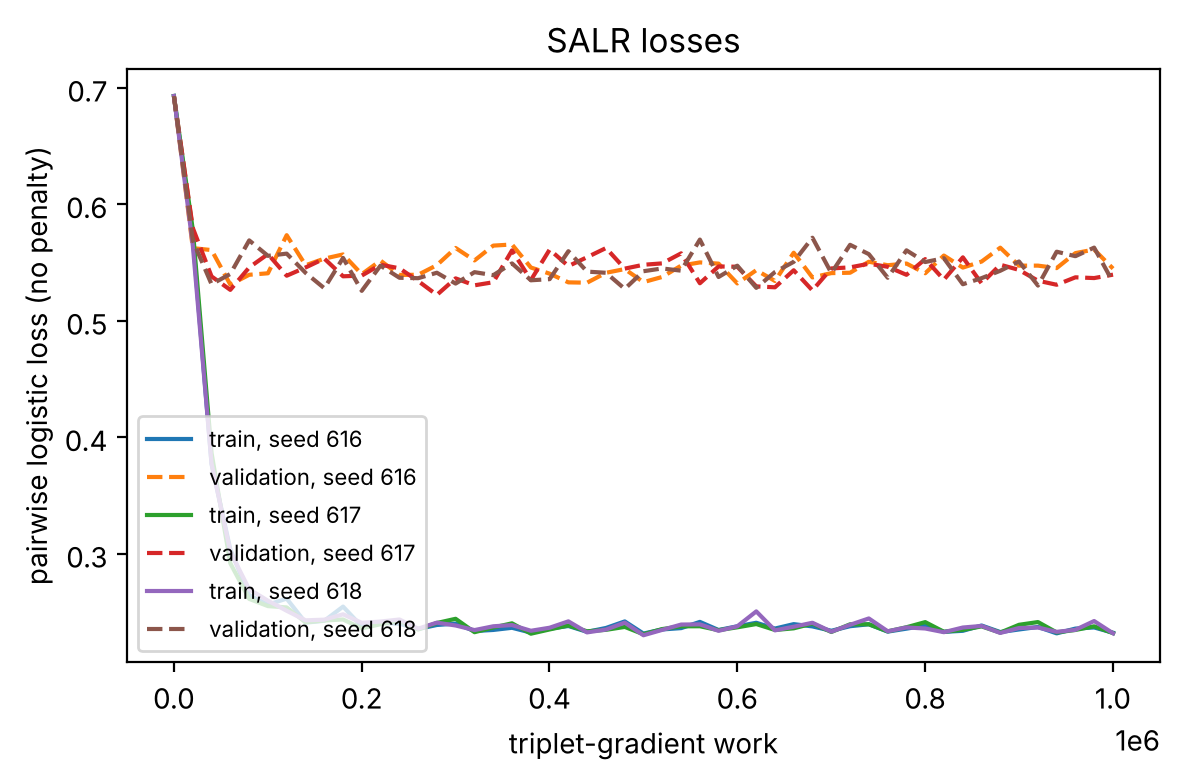

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for seed in SEEDS:
    ck = logs[(chosen, seed)]["checkpoints"]
    ax.plot([c["work"] for c in ck], [c["train_loss"] for c in ck], label=f"train, seed {seed}")
    ax.plot([c["work"] for c in ck], [c["val_loss"] for c in ck], "--", label=f"validation, seed {seed}")
ax.set(xlabel="triplet-gradient work", ylabel="pairwise logistic loss (no penalty)", title="SALR losses")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(RESULTS / "salr_losses.png", dpi=150)